# Forecast Error Analysis

This notebook analyzes forecast errors from the 28-day evaluation period to identify where forecasts are inaccurate and what demand characteristics are associated with higher forecast error.

The analysis is designed to answer **Business Question 3:**

> Where are forecast errors highest, and what demand patterns are associated with those errors?

The analysis builds on the historical demand patterns identified in the demand analysis and examines whether those patterns are associated with forecast error during the unseen evaluation period.

The analysis compares the three practical forecasting methods:

- Naive Forecast
- 7-Day Moving Average
- Seasonal Naive Forecast

The objective is to support demand planning decisions by identifying where simple forecasting approaches perform differently and where additional attention may be required.

> Historical demand patterns are treated as analytical hypotheses rather than assumptions that they will always repeat in the future. The 28-day evaluation period is used to examine whether these patterns are associated with forecast error.


## 2. Load Forecast Results & Required Data

The exported forecast results contain actual demand and forecasts generated by the three practical forecasting methods for the 28-day evaluation period.

The calendar dataset will be used for time-based and event-related error analysis.

The selling-price dataset will be used later to investigate whether selling-price levels or price changes are associated with forecast error.

The datasets are kept separate and will be joined only when required for a specific analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [7]:
forecast_results = pd.read_csv(
    "../data/processed/analytical/forecast_results.csv"
)

calendar = pd.read_csv(
    "../data/processed/cleaned/calendar.csv",
    parse_dates=["date"]
)

sell_prices = pd.read_csv(
    "../data/raw/sell_prices.csv"
)

In [3]:
forecast_results.shape, calendar.shape, sell_prices.shape

((853720, 8), (1969, 14), (6841121, 4))

In [4]:
sell_prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


## 3. Define Forecast Error

Forecast error measures the difference between actual demand and forecast demand during the evaluation period.

The analysis will examine both:

- **Error magnitude** — how far the forecast was from actual demand.
- **Error direction** — whether demand was over-forecast or under-forecast.

The three forecasting methods will be evaluated separately:

- Naive Forecast
- 7-Day Moving Average
- Seasonal Naive Forecast

WAPE and MAE will be used to measure forecast error, while Forecast Bias will be used to identify systematic over- or under-forecasting.

In [5]:
forecast_results["error_naive"] = (
    forecast_results["forecast_naive"]
    - forecast_results["actual_demand"]
)

forecast_results["error_moving_average"] = (
    forecast_results["forecast_moving_average"]
    - forecast_results["actual_demand"]
)

forecast_results["error_seasonal_naive"] = (
    forecast_results["forecast_seasonal_naive"]
    - forecast_results["actual_demand"]
)

In [6]:
forecast_results[
    [
        "actual_demand",
        "forecast_naive",
        "error_naive",
        "forecast_moving_average",
        "error_moving_average",
        "forecast_seasonal_naive",
        "error_seasonal_naive"
    ]
].head()

,actual_demand,forecast_naive,error_naive,forecast_moving_average,error_moving_average,forecast_seasonal_naive,error_seasonal_naive
0,2,0,-2,1.142857,-0.857143,4,2
1,0,0,0,1.142857,1.142857,1,1
2,0,0,0,1.142857,1.142857,1,1
3,0,0,0,1.142857,1.142857,0,0
4,0,0,0,1.142857,1.142857,1,1


In [7]:
forecast_results.shape

(853720, 11)

### 3.1 Create Absolute Errors

In [8]:
forecast_results["absolute_error_naive"] = (
    forecast_results["error_naive"].abs()
)

forecast_results["absolute_error_moving_average"] = (
    forecast_results["error_moving_average"].abs()
)

forecast_results["absolute_error_seasonal_naive"] = (
    forecast_results["error_seasonal_naive"].abs()
)

In [9]:
forecast_results[
    [
        "error_naive",
        "absolute_error_naive",
        "error_moving_average",
        "absolute_error_moving_average",
        "error_seasonal_naive",
        "absolute_error_seasonal_naive"
    ]
].head()

,error_naive,absolute_error_naive,error_moving_average,absolute_error_moving_average,error_seasonal_naive,absolute_error_seasonal_naive
0,-2,2,-0.857143,0.857143,2,2
1,0,0,1.142857,1.142857,1,1
2,0,0,1.142857,1.142857,1,1
3,0,0,1.142857,1.142857,0,0
4,0,0,1.142857,1.142857,1,1


In [10]:
forecast_results.shape

(853720, 14)

## 4. Overall Forecast Error

We'll calculate the three core measures for each forecasting method:

- WAPE → overall error relative to actual demand
- MAE → average absolute error in units
- Bias → systematic over/under-forecasting

In [11]:
forecast_metrics = pd.DataFrame({
    "Method": [
        "Naive Forecast",
        "7-Day Moving Average",
        "Seasonal Naive"
    ],
    "WAPE": [
        (
            forecast_results["absolute_error_naive"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100,
        (
            forecast_results["absolute_error_moving_average"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100,
        (
            forecast_results["absolute_error_seasonal_naive"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100
    ],
    "MAE": [
        forecast_results["absolute_error_naive"].mean(),
        forecast_results["absolute_error_moving_average"].mean(),
        forecast_results["absolute_error_seasonal_naive"].mean()
    ],
    "Bias": [
        (
            forecast_results["error_naive"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100,
        (
            forecast_results["error_moving_average"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100,
        (
            forecast_results["error_seasonal_naive"].sum()
            / forecast_results["actual_demand"].sum()
        ) * 100
    ]
})

forecast_metrics

,Method,WAPE,MAE,Bias
0,Naive Forecast,95.162060,1.373017,13.192137
1,7-Day Moving Average,74.041711,1.068288,-7.359202
2,Seasonal Naive,86.218139,1.243972,-7.359202


##### Overall Forecast Error — Key Observations

- The three forecasting methods show different levels and directions of forecast error during the 28-day evaluation period.
- The 7-Day Moving Average has the lowest observed WAPE and MAE among the three methods for this evaluation period.
- The Naive Forecast shows positive bias, indicating overall over-forecasting, while the 7-Day Moving Average and Seasonal Naive methods show negative bias, indicating overall under-forecasting.
- These overall metrics provide the baseline for investigating where forecast errors are concentrated and what demand characteristics are associated with them.

## 5. Forecast Error Distribution

Overall WAPE, MAE, and Bias summarize forecast performance, but they do not show how errors are distributed across individual Product × Store × Day observations.

This section examines the distribution of forecast errors for the three forecasting methods to understand:

- the typical magnitude of forecast error
- the spread of errors
- over-forecasting versus under-forecasting
- whether a small number of observations have unusually large errors

The analysis will focus on absolute error for error magnitude and signed error for forecast direction.

In [12]:
# summarize absolute error

error_distribution = forecast_results[
    [
        "absolute_error_naive",
        "absolute_error_moving_average",
        "absolute_error_seasonal_naive"
    ]
].describe()

error_distribution

,absolute_error_naive,absolute_error_moving_average,absolute_error_seasonal_naive
count,853720.000000,853720.000000,853720.000000
mean,1.373017,1.068288,1.243972
std,2.547058,1.978714,2.370297
min,0.000000,0.000000,0.000000
25%,0.000000,0.142857,0.000000
50%,1.000000,0.571429,1.000000
75%,2.000000,1.142857,2.000000
max,131.000000,146.000000,153.000000


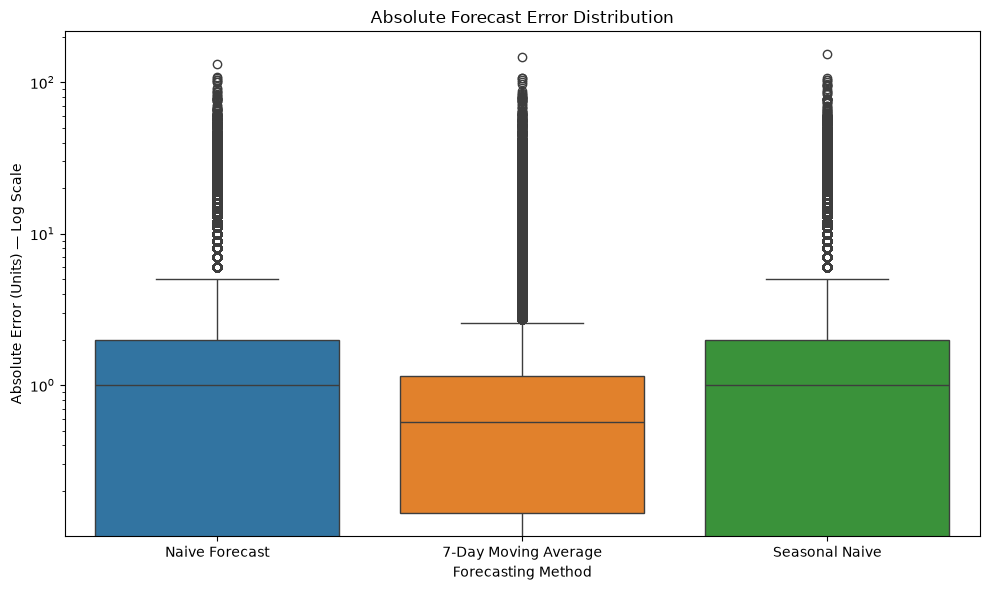

In [13]:
# visualize the distribution

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=forecast_results[
        [
            "absolute_error_naive",
            "absolute_error_moving_average",
            "absolute_error_seasonal_naive"
        ]
    ]
)

plt.yscale("log")

plt.title("Absolute Forecast Error Distribution")
plt.xlabel("Forecasting Method")
plt.ylabel("Absolute Error (Units) — Log Scale")

plt.xticks(
    [0, 1, 2],
    [
        "Naive Forecast",
        "7-Day Moving Average",
        "Seasonal Naive"
    ])

plt.tight_layout()
plt.show()

##### Forecast Error Distribution — Key Observations

- The absolute forecast error distributions are strongly right-skewed across all three forecasting methods.
- The 7-Day Moving Average shows a lower central error distribution than the Naive and Seasonal Naive methods during the evaluation period. However, all three methods contain a substantial number of high-error observations.
- The high-error observations are retained for further analysis rather than removed as outliers. Subsequent analysis will investigate whether these errors are associated with demand volume, intermittency, volatility, product characteristics, store characteristics, time patterns, events, or selling prices.

### 5.1 Forecast Direction

Absolute error shows how large the forecast error is, but it does not indicate whether demand was overestimated or underestimated.

This analysis classifies each forecast observation as:

- Over-forecast: forecast is greater than actual demand (Error > 0)
- Under-forecast: forecast is lower than actual demand (Error < 0)
- Exact forecast: forecast equals actual demand (Error = 0)

The purpose is to understand whether each forecasting method has a consistent directional tendency.

In [14]:
direction_summary = pd.DataFrame({
    "Method": [
        "Naive Forecast",
        "7-Day Moving Average",
        "Seasonal Naive"
    ],
    "Over_Forecast": [
        (forecast_results["error_naive"] > 0).sum(),
        (forecast_results["error_moving_average"] > 0).sum(),
        (forecast_results["error_seasonal_naive"] > 0).sum()
    ],
    "Under_Forecast": [
        (forecast_results["error_naive"] < 0).sum(),
        (forecast_results["error_moving_average"] < 0).sum(),
        (forecast_results["error_seasonal_naive"] < 0).sum()
    ],
    "Exact_Forecast": [
        (forecast_results["error_naive"] == 0).sum(),
        (forecast_results["error_moving_average"] == 0).sum(),
        (forecast_results["error_seasonal_naive"] == 0).sum()
    ]
})

direction_summary

,Method,Over_Forecast,Under_Forecast,Exact_Forecast
0,Naive Forecast,269907,214707,369106
1,7-Day Moving Average,450936,277635,125149
2,Seasonal Naive,220304,242648,390768


In [15]:
direction_percentage = direction_summary.copy()

direction_percentage[
    ["Over_Forecast", "Under_Forecast", "Exact_Forecast"]
] = (
    direction_percentage[
        ["Over_Forecast", "Under_Forecast", "Exact_Forecast"]
    ]
    .div(len(forecast_results))
    .mul(100)
)

direction_percentage

,Method,Over_Forecast,Under_Forecast,Exact_Forecast
0,Naive Forecast,31.615401,25.149581,43.235019
1,7-Day Moving Average,52.820128,32.520616,14.659256
2,Seasonal Naive,25.805182,28.422434,45.772384


##### Forecast Direction — Key Observations

- The frequency of over- and under-forecasting differs across the three methods.
- The 7-Day Moving Average produced over-forecasts in 52.8% of observations and under-forecasts in 32.5% of observations. However, its overall Bias was negative, showing that error frequency and error magnitude can lead to different conclusions about directional forecast behavior.
- The Naive and Seasonal Naive methods had exact forecasts for approximately 43% and 46% of observations respectively, partly reflecting the zero-demand and repeated-demand patterns present in the data.
- Forecast direction will therefore be considered alongside error magnitude rather than used independently to evaluate forecast performance.

## 6. Product / Category / Department Error Analysis

Overall forecast error does not show whether errors are concentrated in particular parts of the product hierarchy.

This section examines forecast performance across categories, departments, products, and individual Product × Store demand series.

The analysis will compare the three forecasting methods using WAPE, MAE, and Forecast Bias to identify where forecast errors are concentrated.

The product hierarchy will be used as a drill-down from broad product categories to individual demand series.

### 6.1 Load the product hierarchy

In [16]:
sales_historical = pd.read_csv(
    "../data/processed/analytical/sales_historical.csv",
    usecols=[
        "item_id",
        "dept_id",
        "cat_id",
        "store_id"
    ]
)

In [17]:
# create a unique mapping

product_mapping = (
    sales_historical
    .drop_duplicates()
)

product_mapping.shape

(30490, 4)

In [18]:
product_mapping.head()

,item_id,dept_id,cat_id,store_id
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1


### 6.2 Category-Level Forecast Error

In [19]:
# merge the mapping

forecast_error = forecast_results.merge(
    product_mapping,
    on=["item_id", "store_id"],
    how="left"
)

forecast_error.shape

(853720, 16)

In [20]:
forecast_error[
    ["cat_id", "dept_id"]
].isna().sum()

cat_id     0
dept_id    0
dtype: int64

In [21]:
# calculate category-level metrics

category_error = (
    forecast_error
    .groupby("cat_id")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

category_error

,cat_id,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,FOODS,86.776987,67.351876,78.665638,1.795427,1.393519,1.627602,9.828850,-9.027878,-9.027878
1,HOBBIES,127.922594,102.954160,118.645560,0.936827,0.753973,0.868887,13.178428,-5.089076,-5.089076
2,HOUSEHOLD,106.399690,81.872940,95.146426,1.028646,0.791528,0.919853,23.076706,-3.385788,-3.385788


##### Category-Level Forecast Error — Key Observations

- Forecast error varies across the three product categories.
- FOODS shows lower WAPE across all three forecasting methods than HOBBIES and HOUSEHOLD during the evaluation period. HOBBIES has the highest WAPE across the three methods.
- Forecast bias also differs by category. The Naive Forecast shows positive bias across all categories, with the highest positive bias in HOUSEHOLD. The 7-Day Moving Average and Seasonal Naive methods show negative bias across all three categories.
- These differences indicate that forecast performance varies across product categories, but category alone does not explain why errors occur. Further analysis will examine department-level differences and demand characteristics associated with forecast error.

### 6.3 Department-Level Forecast Error

In [22]:
department_error = (
    forecast_error
    .groupby("dept_id")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

department_error

,dept_id,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,FOODS_1,96.055061,80.903905,93.053859,1.625678,1.369253,1.574884,-12.875272,-20.409539,-20.409539
1,FOODS_2,100.078691,76.298770,89.629728,1.483606,1.131083,1.328706,9.709872,-12.011283,-12.011283
2,FOODS_3,81.206034,62.280015,72.852374,1.990774,1.526801,1.785983,13.977406,-6.093187,-6.093187
3,HOBBIES_1,125.153578,99.502980,116.003276,1.101906,0.876067,1.021343,15.381165,-2.825828,-2.825828
4,HOBBIES_2,149.270786,129.561613,139.016689,0.475935,0.413094,0.443241,-3.803939,-22.537964,-22.537964
5,HOUSEHOLD_1,96.701255,72.600847,86.292263,1.443294,1.083588,1.287936,23.358836,-3.139070,-3.139070
6,HOUSEHOLD_2,141.693811,115.615537,127.368111,0.600312,0.489827,0.539619,22.049989,-4.283633,-4.283633


##### Department-Level Forecast Error — Key Observations

- Forecast error varies within product categories as well as across categories.
- Within FOODS, forecast performance differs across the three departments, while HOBBIES_2 and HOUSEHOLD_2 show relatively high WAPE compared with their corresponding departments.
- The results also demonstrate the importance of interpreting WAPE together with MAE. Some departments have high WAPE but relatively low MAE, indicating that percentage-based error can become large when demand volumes are low or intermittent.
- Forecast bias also varies by department, with both positive and negative directional patterns observed across the forecasting methods.
- These differences suggest that demand characteristics such as volume and intermittency should be examined alongside product hierarchy when diagnosing forecast error.

### 6.4 Product-level Forecast Error

In [23]:
product_error = (
    forecast_error
    .groupby("item_id")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            )
        }),
        include_groups=False
    )
    .reset_index()
)

In [24]:
product_error.shape

(3049, 10)

In [25]:
product_error.isna().sum()

item_id                0
Naive_WAPE             7
Moving_Average_WAPE    7
Seasonal_Naive_WAPE    7
Naive_MAE              0
Moving_Average_MAE     0
Seasonal_Naive_MAE     0
Naive_Bias             7
Moving_Average_Bias    7
Seasonal_Naive_Bias    7
dtype: int64

> **Metric note:** Seven products had zero actual demand throughout the 28-day evaluation period. WAPE and percentage Bias are therefore undefined for these products because their actual-demand denominator is zero. MAE remains valid and these products are retained for further analysis.

In [26]:
product_error[
    [
        "Naive_WAPE",
        "Moving_Average_WAPE",
        "Seasonal_Naive_WAPE"
    ]
].describe()

,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
count,3042.000000,3042.000000,3042.000000
mean,135.449958,109.675019,121.905839
std,102.507477,43.216600,42.658551
min,25.546106,21.108173,22.577956
25%,100.000000,81.195608,97.697148
50%,121.157341,104.045788,117.958734
75%,155.161362,132.786885,142.857143
max,4100.000000,753.125000,778.125000


##### Product-Level Forecast Error — Key Observations

- Product-level forecast error is highly dispersed across the evaluation period.
- Among the 3,042 products with positive actual demand, the 7-Day Moving Average has the lowest mean and median WAPE of the three methods. However, all methods show a right-skewed WAPE distribution with some extremely high percentage errors.
- The large WAPE values should be interpreted alongside demand volume and intermittency because percentage-based error can become very large for low-volume or intermittent products.
- This indicates that product-level forecast performance alone is not sufficient to explain forecast difficulty. The analysis will therefore continue at the Product × Store level, which matches the forecasting grain used to generate the forecasts.

### 6.5 Product × Store Forecast Error

In [27]:
product_store_error = (
    forecast_error
    .groupby(["item_id", "store_id"])
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["actual_demand"].sum(),

            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            ),

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum() * 100
                if x["actual_demand"].sum() > 0
                else float("nan")
            )
        }),
        include_groups=False
    )
    .reset_index()
)

product_store_error

,item_id,store_id,Actual_Demand,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,FOODS_1_001,CA_1,23.0,100.000000,136.024845,160.869565,0.821429,1.117347,1.321429,-100.000000,3.913043e+01,39.130435
1,FOODS_1_001,CA_2,18.0,522.222222,180.952381,233.333333,3.357143,1.163265,1.500000,522.222222,1.222222e+02,122.222222
2,FOODS_1_001,CA_3,27.0,100.000000,100.000000,85.185185,0.964286,0.964286,0.821429,-100.000000,-8.518519e+01,-85.185185
3,FOODS_1_001,CA_4,6.0,366.666667,290.476190,333.333333,0.785714,0.622449,0.714286,366.666667,2.333333e+02,233.333333
4,FOODS_1_001,TX_1,26.0,100.000000,100.000000,100.000000,0.928571,0.928571,0.928571,-100.000000,-1.000000e+02,-100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
30485,HOUSEHOLD_2_516,TX_2,4.0,100.000000,171.428571,200.000000,0.142857,0.244898,0.285714,-100.000000,-4.440892e-14,0.000000
30486,HOUSEHOLD_2_516,TX_3,9.0,100.000000,100.000000,100.000000,0.321429,0.321429,0.321429,-100.000000,-1.000000e+02,-100.000000
30487,HOUSEHOLD_2_516,WI_1,5.0,100.000000,100.000000,100.000000,0.178571,0.178571,0.178571,-100.000000,-1.000000e+02,-100.000000
30488,HOUSEHOLD_2_516,WI_2,2.0,100.000000,271.428571,300.000000,0.071429,0.193878,0.214286,-100.000000,1.000000e+02,100.000000


In [28]:
product_store_error.shape

(30490, 12)

In [29]:
product_store_error["Actual_Demand"].eq(0).sum()

np.int64(812)

In [30]:
product_store_error[
    [
        "Naive_WAPE",
        "Moving_Average_WAPE",
        "Seasonal_Naive_WAPE"
    ]
].describe()

,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
count,29678.000000,29678.000000,29678.000000
mean,154.033311,128.073504,140.038968
std,256.791089,123.122336,127.780836
min,15.675676,14.922995,13.967074
25%,100.000000,82.417582,93.939394
50%,100.000000,100.000000,106.896552
75%,111.764706,136.734694,150.000000
max,13900.000000,6100.000000,6200.000000


##### Product × Store Forecast Error — Key Observations

- Forecast performance varies substantially across the 30,490 Product × Store demand series.
- A total of 812 Product × Store series had zero actual demand during the 28-day evaluation period, making WAPE undefined for those series. The remaining 29,678 series show a highly dispersed and right-skewed WAPE distribution.
- The large percentage errors observed for some Product × Store series should be interpreted alongside actual demand volume because low-volume demand series can produce very high percentage errors from relatively small absolute errors.
- This suggests that demand volume should be investigated as a potential characteristic associated with forecast error.

## 7. State / Store Error Analysis

### 7.1 State level Forecast Error

In [31]:
store_state_mapping = (
    pd.read_csv(
        "../data/processed/analytical/sales_historical.csv",
        usecols=["store_id", "state_id"]
    )
    .drop_duplicates()
)

store_state_mapping

,store_id,state_id
0,CA_1,CA
3049,CA_2,CA
6098,CA_3,CA
9147,CA_4,CA
12196,TX_1,TX
15245,TX_2,TX
18294,TX_3,TX
21343,WI_1,WI
24392,WI_2,WI
27441,WI_3,WI


In [32]:
forecast_error = forecast_error.merge(
    store_state_mapping,
    on="store_id",
    how="left"
)

In [33]:
forecast_error["state_id"].isna().sum()

np.int64(0)

In [34]:
state_error = (
    forecast_error
    .groupby("state_id")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

state_error

,state_id,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,CA,100.191108,74.813318,87.498513,1.529090,1.141781,1.335379,24.572788,-4.378226,-4.378226
1,TX,92.823900,74.995067,86.808703,1.193838,0.964536,1.116475,4.401046,-8.736821,-8.736821
2,WI,90.306798,72.162954,83.957292,1.344098,1.074051,1.249594,5.229082,-10.244363,-10.244363


##### State-Level Forecast Error — Key Observations

- Forecast performance varies across the three states during the evaluation period.
- The 7-Day Moving Average shows WAPE values within a relatively narrow range across CA, TX, and WI. The Naive Forecast shows positive bias across all three states, while the 7-Day Moving Average and Seasonal Naive methods show negative bias.
- These results indicate some geographic variation in forecast error, but the differences at the state level are relatively limited compared with the variation observed across individual Product × Store series.
- The analysis therefore continues to the individual store level to examine whether more localized differences are present.

### 7.2 Store level Forecast Error

In [35]:
store_error = (
    forecast_error
    .groupby(["state_id", "store_id"])
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Naive_MAE": x["absolute_error_naive"].mean(),

            "Moving_Average_MAE": (
                x["absolute_error_moving_average"].mean()
            ),

            "Seasonal_Naive_MAE": (
                x["absolute_error_seasonal_naive"].mean()
            ),

            "Naive_Bias": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_Bias": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_Bias": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

store_error

,state_id,store_id,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,CA,CA_1,99.859735,74.981241,86.801659,1.567774,1.177188,1.362765,27.703832,-5.556882,-5.556882
1,CA,CA_2,104.396630,76.006406,87.569967,1.625404,1.183382,1.363421,28.119169,-7.077942,-7.077942
2,CA,CA_3,91.578467,67.258700,80.311359,1.881085,1.381540,1.649651,23.282391,-2.447536,-2.447536
3,CA,CA_4,112.817977,89.316420,104.544878,1.042098,0.825015,0.965680,16.142940,-2.117731,-2.117731
4,TX,TX_1,96.868688,77.544722,89.107053,1.106651,0.885889,1.017980,15.782674,-5.264993,-5.264993
5,TX,TX_2,91.349841,73.964993,85.451769,1.233285,0.998578,1.153657,4.266949,-7.876243,-7.876243
6,TX,TX_3,90.897865,73.880701,86.227596,1.241578,1.009140,1.177787,-4.985850,-12.491210,-12.491210
7,WI,WI_1,102.644872,76.615915,89.491658,1.351942,1.009113,1.178700,21.368859,-5.702394,-5.702394
8,WI,WI_2,81.972515,67.979054,79.807243,1.478447,1.226063,1.439395,-6.767288,-14.487972,-14.487972
9,WI,WI_3,89.400131,73.413324,84.102810,1.201905,0.986976,1.130687,5.510782,-9.001089,-9.001089


##### Store-Level Forecast Error — Key Observations

- Forecast performance varies across individual stores more than it does at the state level.
- For the 7-Day Moving Average, store-level WAPE ranges from approximately 67% to 89%, while MAE ranges from 0.83 to 1.38 units. Forecast Bias is negative across all stores for the 7-Day Moving Average.
- The difference between WAPE and MAE is also visible at the store level. A store can show relatively high percentage error while having a relatively small absolute error, particularly when demand volumes are low.
- These results indicate that store-level differences exist, but they do not by themselves explain the underlying forecast difficulty. The next analysis will examine demand characteristics such as volume, intermittency, and volatility.

## 8. Demand Volume vs Forecast Error

> What demand characteristics are associated with forecast error?

In [36]:
# Create demand-volume groups

product_store_error["Demand_Volume_Group"] = pd.qcut(
    product_store_error["Actual_Demand"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

In [37]:
product_store_error["Demand_Volume_Group"].value_counts(
    sort=False
)

Demand_Volume_Group
Low            8458
Medium-Low     7076
Medium-High    7460
High           7496
Name: count, dtype: int64

In [38]:
# Compare error by demand volume

volume_error = (
    product_store_error
    .groupby("Demand_Volume_Group", observed=False)
    .agg(
        Series_Count=("Actual_Demand", "size"),
        Total_Actual_Demand=("Actual_Demand", "sum"),
        Naive_MAE=("Naive_MAE", "mean"),
        Moving_Average_MAE=("Moving_Average_MAE", "mean"),
        Seasonal_Naive_MAE=("Seasonal_Naive_MAE", "mean")
    )
    .reset_index()
)

volume_error

,Demand_Volume_Group,Series_Count,Total_Actual_Demand,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE
0,Low,8458,35220.0,0.309884,0.274666,0.282083
1,Medium-Low,7076,92301.0,0.738770,0.617160,0.674165
2,Medium-High,7460,209065.0,1.261370,0.975871,1.149804
3,High,7496,895178.0,3.282408,2.481586,2.960903


In [39]:
volume_wape = (
    forecast_error
    .merge(
        product_store_error[
            ["item_id", "store_id", "Demand_Volume_Group"]
        ],
        on=["item_id", "store_id"],
        how="left"
    )
    .groupby("Demand_Volume_Group", observed=False)
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

volume_wape

,Demand_Volume_Group,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,Low,208.370244,184.688894,189.676320
1,Medium-Low,158.580080,132.476045,144.712408
2,Medium-High,126.025399,97.500709,114.878626
3,High,76.961007,58.184533,69.422841


##### Demand Volume vs Forecast Error — Key Observations

- Demand volume shows a clear relationship with forecast error during the evaluation period.
- As Product × Store demand volume increases, MAE increases, indicating larger forecast errors in absolute units. However, WAPE decreases substantially as demand volume increases.
- This means that lower-volume demand series have relatively small absolute errors but much larger percentage errors, while higher-volume series have larger absolute errors but lower errors relative to their demand volume.
- The result explains why extremely high WAPE values were observed for some low-volume Product × Store series. Therefore, WAPE should be interpreted alongside MAE when diagnosing forecast error.

## 9. Demand Intermittency vs Forecast Error

> Do more intermittent Product × Store demand series have higher forecast error?

In [40]:
sales_historical = pd.read_csv(
    "../data/processed/analytical/sales_historical.csv",
    usecols=[
        "item_id",
        "store_id",
        "demand"
    ]
)

In [41]:
sales_historical.columns

Index(['item_id', 'store_id', 'demand'], dtype='str')

In [42]:
# Create intermittency groups

intermittency = (
    sales_historical
    .groupby(["item_id", "store_id"])
    .agg(
        Total_Days=("demand", "size"),
        Zero_Demand_Days=("demand", lambda x: (x == 0).sum())
    )
    .reset_index()
)

intermittency["Zero_Demand_Pct"] = (
    intermittency["Zero_Demand_Days"]
    / intermittency["Total_Days"]
) * 100

In [43]:
intermittency["Intermittency_Group"] = pd.qcut(
    intermittency["Zero_Demand_Pct"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

In [44]:
intermittency["Intermittency_Group"].value_counts().sort_index()

Intermittency_Group
Low            7628
Medium-Low     7622
Medium-High    7619
High           7621
Name: count, dtype: int64

In [45]:
# Calculate WAPE by Intermittency Group

intermittency_wape = (
    forecast_error
    .merge(
        intermittency[
            ["item_id", "store_id", "Intermittency_Group"]
        ],
        on=["item_id", "store_id"],
        how="left"
    )
    .groupby("Intermittency_Group", observed=False)
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

intermittency_wape

,Intermittency_Group,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,Low,78.725424,59.500189,71.143117
1,Medium-Low,109.151887,84.942735,98.711858
2,Medium-High,128.238968,103.061022,116.143989
3,High,143.468538,122.622977,132.556949


In [46]:
intermittency_error = (
    forecast_error
    .merge(
        intermittency[
            ["item_id", "store_id", "Intermittency_Group"]
        ],
        on=["item_id", "store_id"],
        how="left"
    )
    .groupby("Intermittency_Group", observed=False)
    .agg(
        Naive_MAE=("absolute_error_naive", "mean"),
        Moving_Average_MAE=("absolute_error_moving_average", "mean"),
        Seasonal_Naive_MAE=("absolute_error_seasonal_naive", "mean"),
        Naive_Bias=("error_naive", "mean"),
        Moving_Average_Bias=("error_moving_average", "mean"),
        Seasonal_Naive_Bias=("error_seasonal_naive", "mean")
    )
    .reset_index()
)

intermittency_error

,Intermittency_Group,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,Low,2.733753,2.066154,2.470457,0.465344,-0.194256,-0.194256
1,Medium-Low,1.380131,1.074027,1.248126,0.143223,-0.135126,-0.135126
2,Medium-High,0.877707,0.705381,0.794925,0.106093,-0.058777,-0.058777
3,High,0.499096,0.426578,0.461137,0.046427,-0.036464,-0.036464


##### Demand Intermittency vs Forecast Error — Key Observations

- As intermittency increases, **WAPE increases** across all three forecasting methods.
- As intermittency increases, **MAE decreases**, meaning the absolute error in units is lower for more intermittent demand series.
- Forecast Bias becomes smaller as intermittency increases, with the Moving Average and Seasonal Naive remaining slightly negative across all groups.
- The **7-Day Moving Average has the lowest WAPE and MAE in every intermittency group**.
- Overall, higher intermittency is associated with **higher relative forecast error but lower absolute forecast error**.

## 10. Demand Volatility vs Forecast Error

> Do more volatile Product × Store demand series have higher forecast error?

In [47]:
# Calculate volatility

volatility = (
    sales_historical
    .groupby(["item_id", "store_id"])["demand"]
    .agg(["mean", "std"])
    .reset_index()
)

volatility["CV"] = (
    volatility["std"] / volatility["mean"]
) * 100

In [48]:
volatility["CV"].isna().sum()

np.int64(0)

In [49]:
volatility["Volatility_Group"] = pd.qcut(
    volatility["CV"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

In [50]:
volatility["Volatility_Group"].value_counts().sort_index()

Volatility_Group
Low            7623
Medium-Low     7622
Medium-High    7622
High           7623
Name: count, dtype: int64

In [51]:
# Calculate WAPE, MAE and Bias

volatility_error = (
    forecast_error
    .merge(
        volatility[
            ["item_id", "store_id", "Volatility_Group"]
        ],
        on=["item_id", "store_id"],
        how="left"
    )
    .groupby("Volatility_Group", observed=False)
    .agg(
        Naive_MAE=("absolute_error_naive", "mean"),
        Moving_Average_MAE=("absolute_error_moving_average", "mean"),
        Seasonal_Naive_MAE=("absolute_error_seasonal_naive", "mean"),
        Naive_Bias=("error_naive", "mean"),
        Moving_Average_Bias=("error_moving_average", "mean"),
        Seasonal_Naive_Bias=("error_seasonal_naive", "mean")
    )
    .reset_index()
)

volatility_error

,Volatility_Group,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,Low,2.602284,1.948077,2.324591,0.489243,-0.175343,-0.175343
1,Medium-Low,1.414627,1.117051,1.303557,0.122521,-0.135248,-0.135248
2,Medium-High,0.915470,0.733324,0.830509,0.103741,-0.070079,-0.070079
3,High,0.559632,0.474663,0.517185,0.045829,-0.044049,-0.044049


In [52]:
volatility_wape = (
    forecast_error
    .merge(
        volatility[
            ["item_id", "store_id", "Volatility_Group"]
        ],
        on=["item_id", "store_id"],
        how="left"
    )
    .groupby("Volatility_Group", observed=False)
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

volatility_wape

,Volatility_Group,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,Low,77.941238,58.347028,69.624019
1,Medium-Low,107.864462,85.174486,99.395481
2,Medium-High,127.115159,101.823775,115.318152
3,High,139.658599,118.454344,129.065825


##### Demand Volatility vs Forecast Error — Key Observations

- WAPE increases as demand volatility increases.
- MAE decreases as demand volatility increases.
- Therefore, highly volatile series have higher relative forecast error but lower absolute error.
- Forecast Bias decreases as volatility increases.
- The 7-Day Moving Average has the lowest WAPE and MAE across all volatility groups.
> Higher volatility is associated with higher relative forecast error, but not higher absolute forecast error.

## 11.1 Seasonality / Weekday Pattern vs Forecast Error

> Are forecast errors higher on certain days of the week?

In [53]:
# Add calendar information

forecast_error = forecast_error.merge(
    calendar[["d", "date", "weekday"]],
    on="d",
    how="left"
)

In [54]:
forecast_error[["d", "date", "weekday"]].head()

,d,date,weekday
0,d_1914,2016-04-25,Monday
1,d_1915,2016-04-26,Tuesday
2,d_1916,2016-04-27,Wednesday
3,d_1917,2016-04-28,Thursday
4,d_1918,2016-04-29,Friday


In [55]:
# MAE and Bias

weekday_order = [
    "Saturday",
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

weekday_error = (
    forecast_error
    .groupby("weekday")
    .agg(
        Naive_MAE=("absolute_error_naive", "mean"),
        Moving_Average_MAE=("absolute_error_moving_average", "mean"),
        Seasonal_Naive_MAE=("absolute_error_seasonal_naive", "mean"),
        Naive_Bias=("error_naive", "mean"),
        Moving_Average_Bias=("error_moving_average", "mean"),
        Seasonal_Naive_Bias=("error_seasonal_naive", "mean")
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_error

,weekday,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,Saturday,1.423582,1.177452,1.390292,-0.092768,-0.389287,-0.120089
1,Sunday,1.418022,1.196193,1.418022,-0.112496,-0.409015,-0.112496
2,Monday,1.337881,1.033329,1.238521,0.233224,-0.063295,-0.151689
3,Tuesday,1.344482,1.008571,1.174328,0.338004,0.041485,-0.062947
4,Wednesday,1.353870,1.009795,1.147229,0.375451,0.078932,-0.098541
5,Thursday,1.361438,1.008903,1.129592,0.378969,0.082450,-0.105190
6,Friday,1.371843,1.043775,1.209823,0.211988,-0.084531,-0.092309


In [56]:
# WAPE

weekday_wape = (
    forecast_error
    .groupby("weekday")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_wape

,weekday,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,Saturday,82.482161,68.221422,80.553365
1,Sunday,81.231564,68.524056,81.231564
2,Monday,95.567426,73.812703,88.469918
3,Tuesday,103.808631,77.872640,90.670879
4,Wednesday,107.645870,80.288527,91.215855
5,Thursday,108.551199,80.442634,90.065442
6,Friday,96.529084,73.444756,85.128602


##### Seasonality / Weekday vs Forecast Error — Key Observations

- The demand analysis showed that weekend demand was approximately 31% higher than weekday demand.
- Using this finding as a hypothesis, forecast error was compared across the days of the week.
- Forecast WAPE was generally higher on weekdays, particularly Tuesday–Thursday, while weekend WAPE was lower across the three forecasting methods.
- Therefore, the weekday/weekend demand pattern identified in the EDA is associated with differences in forecast error during the evaluation period. However, higher weekend demand did not correspond to higher relative forecast error.
> Forecast errors are generally higher on weekdays, particularly Tuesday–Thursday, than on weekends during the evaluation period.

## 11.2 Seasonality / Within-Month Pattern vs Forecast Error

The demand analysis showed that demand was higher at the beginning of the month and declined toward the end.

This finding is tested against forecast error by comparing forecast performance across three parts of the month:

- Beginning of month
- Middle of month
- End of month

The comparison uses WAPE, MAE, and Forecast Bias.

In [110]:
calendar["day_of_month"] = calendar["date"].dt.day
calendar["days_in_month"] = calendar["date"].dt.days_in_month

calendar["Month_Period"] = np.select(
    [
        calendar["day_of_month"] <= 7,
        calendar["day_of_month"] > calendar["days_in_month"] - 7
    ],
    [
        "Start of Month",
        "End of Month"
    ],
    default="Middle of Month"
)

calendar["Month_Period"] = pd.Categorical(
    calendar["Month_Period"],
    categories=[
        "Start of Month",
        "Middle of Month",
        "End of Month"
    ],
    ordered=True
)

In [111]:
forecast_error = forecast_error.merge(
    calendar[["d", "Month_Period"]],
    on="d",
    how="left"
)

In [112]:
forecast_error["Month_Period"].value_counts().sort_index()

Month_Period
Start of Month     213430
Middle of Month    457350
End of Month       182940
Name: count, dtype: int64

In [113]:
forecast_error["Month_Period"].isna().sum()

np.int64(0)

In [114]:
within_month_error = (
    forecast_error
    .groupby("Month_Period", observed=True)
    .apply(
        lambda x: pd.Series({
            "WAPE_Naive": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE_Naive": x["absolute_error_naive"].mean(),
            "Bias_Naive": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Moving_Average": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE_Moving_Average": x["absolute_error_moving_average"].mean(),
            "Bias_Moving_Average": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Seasonal_Naive": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE_Seasonal_Naive": x["absolute_error_seasonal_naive"].mean(),
            "Bias_Seasonal_Naive": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        })
    )
    .reset_index()
)

within_month_error

,Month_Period,WAPE_Naive,MAE_Naive,Bias_Naive,WAPE_Moving_Average,MAE_Moving_Average,Bias_Moving_Average,WAPE_Seasonal_Naive,MAE_Seasonal_Naive,Bias_Seasonal_Naive
0,Start of Month,91.843166,1.372441,9.290294,72.185062,1.078684,-10.552620,83.925565,1.254125,-10.552620
1,Middle of Month,94.803172,1.401364,10.484182,74.343690,1.098936,-9.575497,86.435115,1.277669,-8.238185
2,End of Month,100.657145,1.302821,26.179355,75.680342,0.979542,3.270036,88.686640,1.147885,-0.548184


##### Within-Month Pattern — Key Observations

The demand analysis showed that demand was higher at the beginning of the month and declined toward the end.

During the evaluation period:

- WAPE increased from the beginning to the end of the month for all three forecasting methods.
- Naive WAPE increased from 91.84% to 100.66%.
- 7-Day Moving Average WAPE increased from 72.19% to 75.68%.
- Seasonal Naive WAPE increased from 83.93% to 88.69%.
- MAE showed a different pattern, with the highest values generally occurring in the middle of the month.

The within-month demand pattern identified in the EDA is therefore associated with differences in forecast error across the month.

## 12. Event Analysis vs Forecast Error

> Are event periods associated with higher forecast error?

In [57]:
# Add event information

event_columns = [
    "d",
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]

forecast_error = forecast_error.merge(
    calendar[event_columns],
    on="d",
    how="left"
)

In [58]:
# Create an event indicator

forecast_error["Event_Day"] = (
    forecast_error["event_name_1"].notna()
    | forecast_error["event_name_2"].notna()
)

In [59]:
forecast_error["Event_Day"].value_counts()

Event_Day
False    731760
True     121960
Name: count, dtype: int64

In [60]:
# Calculate WAPE, MAE and Bias

event_error = (
    forecast_error
    .groupby("Event_Day")
    .agg(
        Naive_MAE=("absolute_error_naive", "mean"),
        Moving_Average_MAE=("absolute_error_moving_average", "mean"),
        Seasonal_Naive_MAE=("absolute_error_seasonal_naive", "mean"),
        Naive_Bias=("error_naive", "mean"),
        Moving_Average_Bias=("error_moving_average", "mean"),
        Seasonal_Naive_Bias=("error_seasonal_naive", "mean")
    )
    .reset_index()
)

event_error

,Event_Day,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,False,1.375258,1.064025,1.234331,0.209289,-0.087230,-0.115338
1,True,1.359569,1.093868,1.301820,0.076640,-0.219879,-0.051230


In [61]:
event_wape = (
    forecast_error
    .groupby("Event_Day")
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

event_wape

,Event_Day,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,False,96.585954,74.727693,86.688466
1,True,87.346773,70.276581,83.636670


###### Event vs Forecast Error — Key Observations

- WAPE is lower on event days than on non-event days across all three methods.
- MAE is slightly higher on event days for the Moving Average and Seasonal Naive methods, but slightly lower for the Naive method.
- Forecast Bias is smaller on event days for the Naive and Seasonal Naive methods, while the Moving Average becomes more negative.
- The 7-Day Moving Average has the lowest WAPE on both event and non-event days.
> The EDA finding that event days had different demand variability is not associated with higher relative forecast error in this evaluation period. Event days actually show lower WAPE than non-event days

## 13. SNAP Analysis vs Forecast Error

The demand analysis showed higher average demand on SNAP-active days across California, Texas, and Wisconsin.

This analysis examines whether SNAP-active days were also associated with differences in forecast error during the 28-day evaluation period.

> EDA found higher demand on SNAP-active days. Does forecast error also differ on SNAP-active days?

In [144]:
snap_error = forecast_error[
    [
        "state_id",
        "d",
        "actual_demand",
        "error_naive",
        "error_moving_average",
        "error_seasonal_naive",
        "absolute_error_naive",
        "absolute_error_moving_average",
        "absolute_error_seasonal_naive"
    ]
].copy()

snap_error = snap_error.merge(
    calendar[
        ["d", "snap_CA", "snap_TX", "snap_WI"]
    ],
    on="d",
    how="left"
)

snap_error["SNAP_Active"] = np.select(
    [
        snap_error["state_id"] == "CA",
        snap_error["state_id"] == "TX",
        snap_error["state_id"] == "WI"
    ],
    [
        snap_error["snap_CA"],
        snap_error["snap_TX"],
        snap_error["snap_WI"]
    ],
    default=np.nan
)

snap_error.head()

,state_id,d,actual_demand,error_naive,error_moving_average,error_seasonal_naive,absolute_error_naive,absolute_error_moving_average,absolute_error_seasonal_naive,snap_CA,snap_TX,snap_WI,SNAP_Active
0,CA,d_1914,2,-2,-0.857143,2,2,0.857143,2,0,0,0,0.0
1,CA,d_1915,0,0,1.142857,1,0,1.142857,1,0,0,0,0.0
2,CA,d_1916,0,0,1.142857,1,0,1.142857,1,0,0,0,0.0
3,CA,d_1917,0,0,1.142857,0,0,1.142857,0,0,0,0,0.0
4,CA,d_1918,0,0,1.142857,1,0,1.142857,1,0,0,0,0.0


In [145]:
snap_error_summary = (
    snap_error
    .groupby(["state_id", "SNAP_Active"])
    .agg(
        Actual_Demand=("actual_demand", "sum"),

        Absolute_Error_Naive=("absolute_error_naive", "sum"),
        Absolute_Error_Moving_Average=("absolute_error_moving_average", "sum"),
        Absolute_Error_Seasonal_Naive=("absolute_error_seasonal_naive", "sum"),

        MAE_Naive=("absolute_error_naive", "mean"),
        MAE_Moving_Average=("absolute_error_moving_average", "mean"),
        MAE_Seasonal_Naive=("absolute_error_seasonal_naive", "mean"),

        Bias_Naive=("error_naive", "mean"),
        Bias_Moving_Average=("error_moving_average", "mean"),
        Bias_Seasonal_Naive=("error_seasonal_naive", "mean")
    )
    .reset_index()
)

In [146]:
snap_error_summary["WAPE_Naive"] = (
    snap_error_summary["Absolute_Error_Naive"]
    / snap_error_summary["Actual_Demand"]
) * 100

snap_error_summary["WAPE_Moving_Average"] = (
    snap_error_summary["Absolute_Error_Moving_Average"]
    / snap_error_summary["Actual_Demand"]
) * 100

snap_error_summary["WAPE_Seasonal_Naive"] = (
    snap_error_summary["Absolute_Error_Seasonal_Naive"]
    / snap_error_summary["Actual_Demand"]
) * 100

snap_error_summary

,state_id,SNAP_Active,Actual_Demand,Absolute_Error_Naive,Absolute_Error_Moving_Average,Absolute_Error_Seasonal_Naive,MAE_Naive,MAE_Moving_Average,MAE_Seasonal_Naive,Bias_Naive,Bias_Moving_Average,Bias_Seasonal_Naive,WAPE_Naive,WAPE_Moving_Average,WAPE_Seasonal_Naive
0,CA,0.0,330467,336267,250231.857143,291100,1.531773,1.139863,1.326027,0.395845,-0.045998,-0.057970,101.755092,75.720679,88.087464
1,CA,1.0,190703,185899,139672.714286,164916,1.524262,1.145234,1.352214,0.337545,-0.104298,-0.082748,97.480900,73.240963,86.477926
2,TX,0.0,203574,194004,155197.428571,180902,1.178310,0.942613,1.098733,0.106301,-0.062670,-0.064429,95.299007,76.236370,88.863018
3,TX,1.0,125825,111757,91835.571429,105045,1.221789,1.003997,1.148409,-0.032852,-0.201823,-0.198655,88.819392,72.986745,83.484999
4,WI,0.0,229345,215095,168643.285714,197151,1.306409,1.024278,1.197424,0.173238,-0.057064,-0.055543,93.786653,73.532576,85.962633
5,WI,1.0,151850,129150,106438.285714,122890,1.411938,1.163641,1.343501,-0.093911,-0.324212,-0.326949,85.051037,70.094360,80.928548


##### SNAP Analysis — Key Observations

- During the 28-day evaluation period, forecast WAPE was lower on SNAP-active days than on non-SNAP days across California, Texas, and Wisconsin for all three forecasting methods.
- The 7-Day Moving Average also showed lower WAPE on SNAP-active days in all three states.
- MAE differences between SNAP-active and non-SNAP days were smaller than the WAPE differences, while forecast bias varied by state and forecasting method.
- These results indicate that SNAP-active days were associated with differences in forecast error during the evaluation period. However, the analysis does not establish that SNAP activity caused the differences, as other demand factors may also contribute to forecast performance.

## 14. Selling Price vs Forecast Error

> Is forecast error associated with selling-price levels or price changes?

In [62]:
# Add wm_yr_wk to forecast data

forecast_error = forecast_error.merge(
    calendar[["d", "wm_yr_wk"]],
    on="d",
    how="left"
)

In [63]:
forecast_error[["d", "wm_yr_wk"]].head()

,d,wm_yr_wk
0,d_1914,11613
1,d_1915,11613
2,d_1916,11613
3,d_1917,11613
4,d_1918,11613


In [64]:
# merge selling prices

forecast_error = forecast_error.merge(
    sell_prices,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left"
)

> Product × Store × Walmart Week

In [65]:
forecast_error[["item_id", "store_id", "wm_yr_wk", "sell_price"]].head()

,item_id,store_id,wm_yr_wk,sell_price
0,FOODS_1_001,CA_1,11613,2.24
1,FOODS_1_001,CA_1,11613,2.24
2,FOODS_1_001,CA_1,11613,2.24
3,FOODS_1_001,CA_1,11613,2.24
4,FOODS_1_001,CA_1,11613,2.24


In [66]:
forecast_error["sell_price"].isna().sum()

np.int64(0)

In [67]:
# Create price groups

price_groups = (
    forecast_error[["item_id", "store_id", "wm_yr_wk", "sell_price"]]
    .drop_duplicates()
)

price_groups["Price_Group"] = pd.qcut(
    price_groups["sell_price"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

In [68]:
price_groups["Price_Group"].value_counts().sort_index()

Price_Group
Low            39457
Medium-Low     37882
Medium-High    37157
High           37954
Name: count, dtype: int64

In [69]:
# Calculate WAPE, MAE and Bias by price group

forecast_error = forecast_error.merge(
    price_groups[
        ["item_id", "store_id", "wm_yr_wk", "Price_Group"]
    ],
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left"
)

In [70]:
price_error = (
    forecast_error
    .groupby("Price_Group", observed=False)
    .agg(
        Naive_MAE=("absolute_error_naive", "mean"),
        Moving_Average_MAE=("absolute_error_moving_average", "mean"),
        Seasonal_Naive_MAE=("absolute_error_seasonal_naive", "mean"),
        Naive_Bias=("error_naive", "mean"),
        Moving_Average_Bias=("error_moving_average", "mean"),
        Seasonal_Naive_Bias=("error_seasonal_naive", "mean")
    )
    .reset_index()
)

price_error

,Price_Group,Naive_MAE,Moving_Average_MAE,Seasonal_Naive_MAE,Naive_Bias,Moving_Average_Bias,Seasonal_Naive_Bias
0,Low,2.213332,1.731679,2.036607,0.191222,-0.225534,-0.225680
1,Medium-Low,1.377059,1.056228,1.234033,0.255377,-0.090185,-0.089946
2,Medium-High,1.053618,0.810920,0.939007,0.194352,-0.043001,-0.043061
3,High,0.807924,0.642504,0.728281,0.120578,-0.059899,-0.059927


In [71]:
price_wape = (
    forecast_error
    .groupby("Price_Group", observed=False)
    .apply(
        lambda x: pd.Series({
            "Naive_WAPE": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Moving_Average_WAPE": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "Seasonal_Naive_WAPE": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

price_wape

,Price_Group,Naive_WAPE,Moving_Average_WAPE,Seasonal_Naive_WAPE
0,Low,85.274530,66.717557,78.465755
1,Medium-Low,98.069278,75.220846,87.883458
2,Medium-High,105.866364,81.480368,94.350408
3,High,112.055867,89.112760,101.009659


##### Price vs Forecast Error — Key Observations

- **WAPE increases as price increases** across all three forecasting methods.
- **MAE decreases as price increases**, meaning higher-priced products have lower absolute forecast error.
- Forecast Bias is positive for the Naive Forecast and negative for the Moving Average and Seasonal Naive methods across all price groups.
- The **7-Day Moving Average has the lowest WAPE and MAE across all price groups**.
> Higher-priced products had **higher relative forecast error but lower absolute forecast error** during the evaluation period.


## 15. Forecast Method × Error Patterns

The previous sections examined how individual demand characteristics were associated with forecast error.

This section compares the three forecasting methods directly across those demand characteristics:

- Demand volume
- Demand intermittency
- Demand volatility
- Weekday pattern
- Event days
- SNAP Periods
- Selling price
- Category
- Department
- Store

The purpose is to identify whether the forecasting methods behave differently under different demand conditions.

The comparison uses WAPE, MAE, and Forecast Bias.

> Do different demand characteristics affect the three forecasting approaches differently?

In [147]:
method_pattern_summary = pd.DataFrame({
    "Pattern": [
        "Demand Volume",
        "Demand Intermittency",
        "Demand Volatility",
        "Weekday",
        "Event Days",
        "SNAP Periods",
        "Selling Price",
        "Category",
        "Department",
        "Store"
    ],

    "Naive Forecast": [
        "WAPE decreases as volume increases",
        "WAPE increases as intermittency increases",
        "WAPE increases as volatility increases",
        "WAPE generally higher on weekdays",
        "Lower WAPE on event days",
        "Lower WAPE on SNAP-active days",
        "WAPE increases as price increases",
        "WAPE varies across categories",
        "WAPE varies across departments",
        "WAPE varies across stores"
    ],

    "7-Day Moving Average": [
        "WAPE decreases as volume increases",
        "WAPE increases as intermittency increases",
        "WAPE increases as volatility increases",
        "WAPE generally higher on weekdays",
        "Lower WAPE on event days",
        "Lower WAPE on SNAP-active days",
        "WAPE increases as price increases",
        "WAPE is lower across categories",
        "WAPE is lower across departments",
        "WAPE is lower across stores"
    ],

    "Seasonal Naive": [
        "WAPE decreases as volume increases",
        "WAPE increases as intermittency increases",
        "WAPE increases as volatility increases",
        "WAPE generally higher on weekdays",
        "Lower WAPE on event days",
        "Lower WAPE on SNAP-active days",
        "WAPE increases as price increases",
        "WAPE is higher than Moving Average across categories",
        "WAPE is higher than Moving Average across departments",
        "WAPE is higher than Moving Average across stores"
    ]
})

method_pattern_summary

,Pattern,Naive Forecast,7-Day Moving Average,Seasonal Naive
0,Demand Volume,WAPE decreases as volume increases,WAPE decreases as volume increases,WAPE decreases as volume increases
1,Demand Intermittency,WAPE increases as intermittency increases,WAPE increases as intermittency increases,WAPE increases as intermittency increases
2,Demand Volatility,WAPE increases as volatility increases,WAPE increases as volatility increases,WAPE increases as volatility increases
3,Weekday,WAPE generally higher on weekdays,WAPE generally higher on weekdays,WAPE generally higher on weekdays
4,Event Days,Lower WAPE on event days,Lower WAPE on event days,Lower WAPE on event days
5,SNAP Periods,Lower WAPE on SNAP-active days,Lower WAPE on SNAP-active days,Lower WAPE on SNAP-active days
6,Selling Price,WAPE increases as price increases,WAPE increases as price increases,WAPE increases as price increases
7,Category,WAPE varies across categories,WAPE is lower across categories,WAPE is higher than Moving Average across cate...
8,Department,WAPE varies across departments,WAPE is lower across departments,WAPE is higher than Moving Average across depa...
9,Store,WAPE varies across stores,WAPE is lower across stores,WAPE is higher than Moving Average across stores


##### Forecast Method x Error Patterns - Key Observations

- The three forecasting methods show similar directional relationships across demand volume, intermittency, volatility, weekday patterns, event days, SNAP periods, and selling price.
- Higher demand volume is associated with lower WAPE, while higher intermittency, volatility, and price are associated with higher WAPE.
- WAPE is generally higher on weekdays and lower on event days across the three methods.
- SNAP-active days showed lower WAPE than non-SNAP days across California, Texas, and Wisconsin for all three forecasting methods during the evaluation period.
- Forecast error varies across categories, departments, and stores.
- The 7-Day Moving Average has lower WAPE than the Naive and Seasonal Naive methods across the hierarchy and demand-characteristic groups examined.
- The Seasonal Naive shows similar directional error patterns to the other methods, but its WAPE remains higher than the 7-Day Moving Average across the groups examined.

> The comparison shows that the three forecasting methods generally respond to demand characteristics in similar directions, while the magnitude of forecast error differs between methods.

> SNAP-active periods were associated with lower relative forecast error during the evaluation period, but this does not establish that SNAP activity caused the difference.

> The 7-Day Moving Average shows lower WAPE across the diagnostic groups examined during the evaluation period.

## 16. High-Error Segmentation

The previous analysis compared the three forecasting methods across different demand characteristics and business segments.

This section focuses on the 7-Day Moving Average forecast and segments Product × Store demand series based on their forecast error during the 28-day evaluation period.

The purpose is to identify what a typical low-, medium-, and high-error demand series looks like.

The segmentation is based on Mean Absolute Error (MAE), with WAPE used as a supporting error measure.

> What does a typical high-error demand series look like?

### Segmentation Approach

Each Product × Store series is assigned to one of three error groups based on its 28-day MAE:

- Low Error
- Medium Error
- High Error

The groups are created using equal-frequency tertiles so that the Product × Store series are distributed approximately evenly across the three groups.

The resulting groups are then profiled using demand volume, intermittency, volatility, category, department, store, state, and time-related characteristics.

In [82]:
# Create the Product × Store error table

series_error = (
    forecast_error
    .groupby(["item_id", "store_id"])
    .agg(
        Actual_Demand=("actual_demand", "sum"),
        Absolute_Error=("absolute_error_moving_average", "sum"),
        MAE=("absolute_error_moving_average", "mean")
    )
    .reset_index()
)

series_error["WAPE"] = (
    series_error["Absolute_Error"]
    / series_error["Actual_Demand"]
) * 100

In [83]:
series_error.shape

(30490, 6)

In [86]:
# Create error groups

series_error["Error_Group"] = pd.qcut(
    series_error["MAE"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [87]:
series_error["Error_Group"].value_counts().sort_index()

Error_Group
Low       10204
Medium    10139
High      10147
Name: count, dtype: int64

In [88]:
series_error.groupby("Error_Group", observed=True)["MAE"].agg(
    ["count", "min", "median", "max"]
)

,count,min,median,max
Error_Group,,,,
Low,10204,0.000000,0.306122,0.535714
Medium,10139,0.540816,0.734694,1.010204
High,10147,1.010204,1.556122,33.112245


### 16.1 Demand Volume Profile

The error groups are compared by total actual demand during the 28-day evaluation period.

This shows whether low-, medium-, and high-error Product × Store series differ in their demand volume.

> Do high-error series have different demand volumes from low-error series?

In [89]:
volume_profile = (
    series_error
    .groupby("Error_Group", observed=True)["Actual_Demand"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max"
    )
    .reset_index()
)

volume_profile

,Error_Group,Count,Mean,Median,Min,Max
0,Low,10204,5.705214,5.0,0,33
1,Medium,10139,19.870303,19.0,0,86
2,High,10147,95.800039,58.0,0,3357


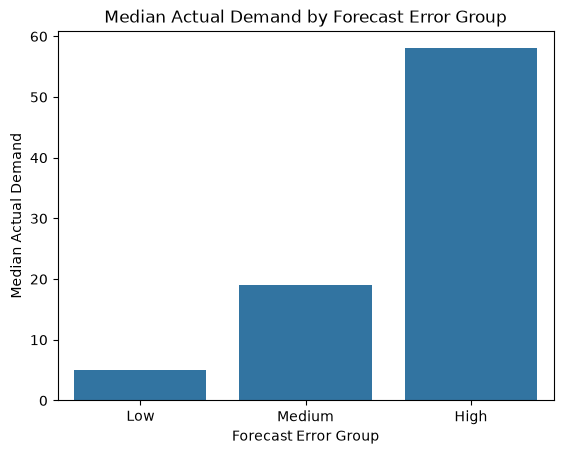

In [90]:
sns.barplot(
    data=volume_profile,
    x="Error_Group",
    y="Median"
)

plt.title("Median Actual Demand by Forecast Error Group")
plt.xlabel("Forecast Error Group")
plt.ylabel("Median Actual Demand")
plt.show()

##### Demand Volume — Key Observation

The median actual demand increases across the forecast error groups.

- Low-error series: 5 units
- Medium-error series: 19 units
- High-error series: 58 units

High-error Product × Store series therefore had substantially higher evaluation-period demand volume than low-error series.

### 16.2 Demand Intermittency Profile

The error groups are compared by the percentage of historical days with zero demand.

This shows whether high-error Product × Store series have different levels of demand intermittency.

> Do high-error group also has different levels of intermittent demand?

In [91]:
intermittency_profile = (
    intermittency
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
    .groupby("Error_Group", observed=True)["Zero_Demand_Pct"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max"
    )
    .reset_index()
)

intermittency_profile

,Error_Group,Count,Mean,Median,Min,Max
0,Low,10204,84.424658,87.767904,13.434396,99.634083
1,Medium,10139,70.224795,72.347099,6.429692,99.163617
2,High,10147,49.849811,49.817041,0.156822,99.006796


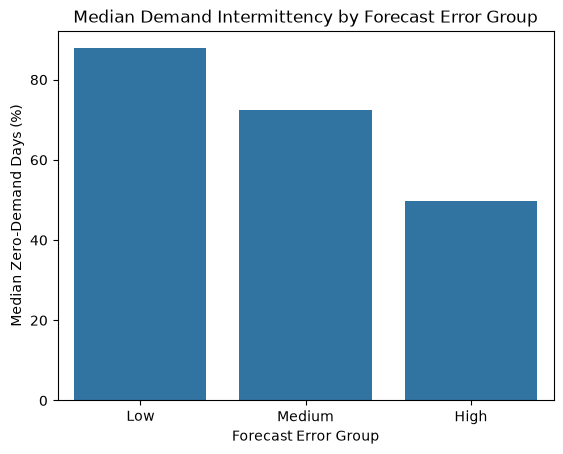

In [92]:
sns.barplot(
    data=intermittency_profile,
    x="Error_Group",
    y="Median"
)

plt.title("Median Demand Intermittency by Forecast Error Group")
plt.xlabel("Forecast Error Group")
plt.ylabel("Median Zero-Demand Days (%)")
plt.show()

##### Demand Intermittency — Key Observation

The median percentage of zero-demand days decreases as forecast error increases.

- Low-error series: 87.77% zero-demand days
- Medium-error series: 72.35% zero-demand days
- High-error series: 49.82% zero-demand days

Therefore, the high-error group contains less intermittent demand series than the low-error group.

### 16.3 Demand Volatility Profile

The error groups are compared by historical demand volatility using the coefficient of variation (CV).

This shows whether low-, medium-, and high-error Product × Store series differ in their historical demand variability.

In [93]:
volatility_profile = (
    volatility
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
    .groupby("Error_Group", observed=True)["CV"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max"
    )
    .reset_index()
)

volatility_profile

,Error_Group,Count,Mean,Median,Min,Max
0,Low,10204,329.377419,300.197206,73.248437,2303.269802
1,Medium,10139,222.929705,197.511612,65.693619,1312.536776
2,High,10147,163.070854,142.591351,25.313216,1128.465929


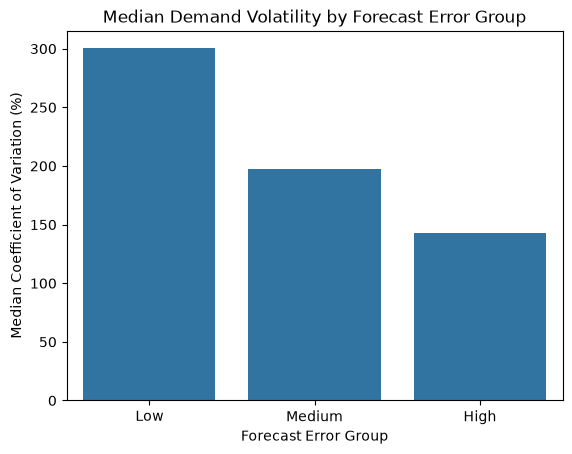

In [94]:
sns.barplot(
    data=volatility_profile,
    x="Error_Group",
    y="Median"
)

plt.title("Median Demand Volatility by Forecast Error Group")
plt.xlabel("Forecast Error Group")
plt.ylabel("Median Coefficient of Variation (%)")
plt.show()

##### Demand Volatility — Key Observation

The median historical demand volatility decreases as the forecast error group increases.

- Low-error series: 300.20% CV
- Medium-error series: 197.51% CV
- High-error series: 142.59% CV

Therefore, the high-error group has lower historical CV than the low-error group when forecast error is measured using MAE.

### 16.4 Category Profile

The error groups are compared across product categories to identify whether the distribution of Low, Medium, and High forecast-error series differs by category.

In [95]:
category_profile = (
    forecast_error[["item_id", "store_id", "cat_id"]]
    .drop_duplicates()
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
)

category_profile = pd.crosstab(
    category_profile["cat_id"],
    category_profile["Error_Group"],
    normalize="index"
).mul(100).reset_index()

category_profile

Error_Group,cat_id,Low,Medium,High
0,FOODS,18.712596,33.862213,47.425191
1,HOBBIES,53.522124,29.451327,17.026549
2,HOUSEHOLD,42.893983,34.469914,22.636103


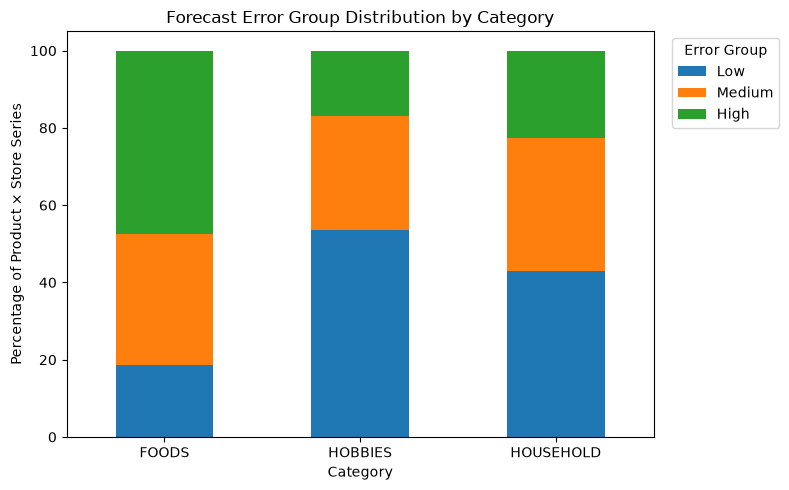

In [99]:
category_profile_plot = category_profile.set_index("cat_id")

ax = category_profile_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Forecast Error Group Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Percentage of Product × Store Series")

ax.legend(
    title="Error Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation= 0)
plt.tight_layout()
plt.show()

##### Category — Key Observation

The distribution of forecast error groups differs across categories.

- FOODS has the highest proportion of High-Error Product × Store series at 47.43%.
- HOBBIES has the highest proportion of Low-Error series at 53.52%.
- HOUSEHOLD has 42.89% Low-Error, 34.47% Medium-Error, and 22.64% High-Error series.

### 16.5 Department Profile

The error groups are compared across departments to identify whether the distribution of Low, Medium, and High forecast-error Product × Store series differs by department.

In [100]:
department_profile = (
    forecast_error[["item_id", "store_id", "dept_id"]]
    .drop_duplicates()
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
)

department_profile = pd.crosstab(
    department_profile["dept_id"],
    department_profile["Error_Group"],
    normalize="index"
).mul(100).reset_index()

department_profile

Error_Group,dept_id,Low,Medium,High
0,FOODS_1,20.277778,34.583333,45.138889
1,FOODS_2,20.326633,36.934673,42.738693
2,FOODS_3,17.521264,32.187120,50.291616
3,HOBBIES_1,45.649038,33.629808,20.721154
4,HOBBIES_2,75.503356,17.785235,6.711409
5,HOUSEHOLD_1,22.969925,39.680451,37.349624
6,HOUSEHOLD_2,63.475728,29.087379,7.436893


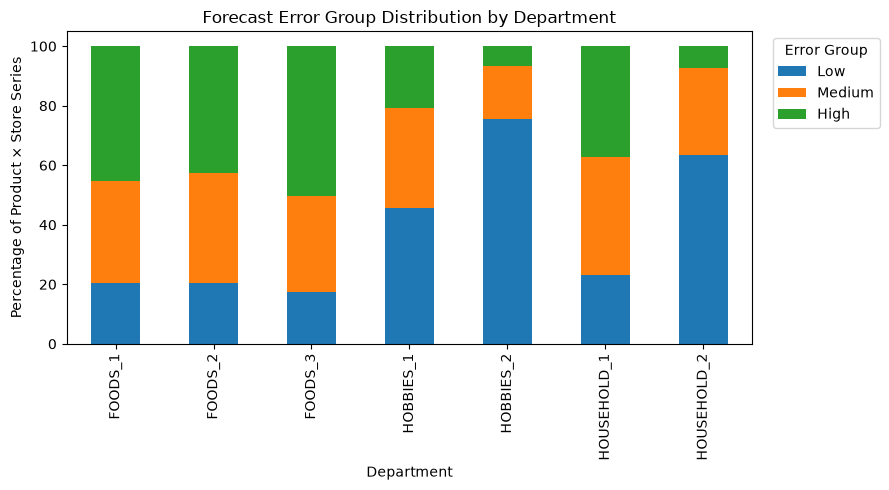

In [103]:
department_profile_plot = department_profile.set_index("dept_id")

ax = department_profile_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Forecast Error Group Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Product × Store Series")

ax.legend(
    title="Error Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### Department — Key Observation

The distribution of forecast error groups differs across departments.

- FOODS_3 has 50.29% of its Product × Store series in the High-Error group.
- FOODS_1 and FOODS_2 also have relatively large proportions of High-Error series at 45.14% and 42.74%.
- HOBBIES_2 and HOUSEHOLD_2 have the largest proportions of Low-Error series at 75.50% and 63.48%, respectively.
- HOBBIES_1 has a more balanced distribution, with 45.65% Low, 33.63% Medium, and 20.72% High.

### 16.6 Store Profile

The error groups are compared across stores to identify whether the distribution of Low, Medium, and High forecast-error Product × Store series differs by store.

In [104]:
store_profile = (
    forecast_error[["item_id", "store_id"]]
    .drop_duplicates()
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
)

store_profile = pd.crosstab(
    store_profile["store_id"],
    store_profile["Error_Group"],
    normalize="index"
).mul(100).reset_index()

store_profile

Error_Group,store_id,Low,Medium,High
0,CA_1,25.483765,35.880617,38.635618
1,CA_2,23.942276,35.257461,40.800262
2,CA_3,21.252870,31.715316,47.031814
3,CA_4,38.701214,36.831748,24.467038
4,TX_1,43.227288,32.141686,24.631027
5,TX_2,35.060676,34.699902,30.239423
6,TX_3,38.438832,31.387340,30.173827
7,WI_1,31.059364,34.634306,34.306330
8,WI_2,36.667760,28.566743,34.765497
9,WI_3,40.833060,31.420138,27.746802


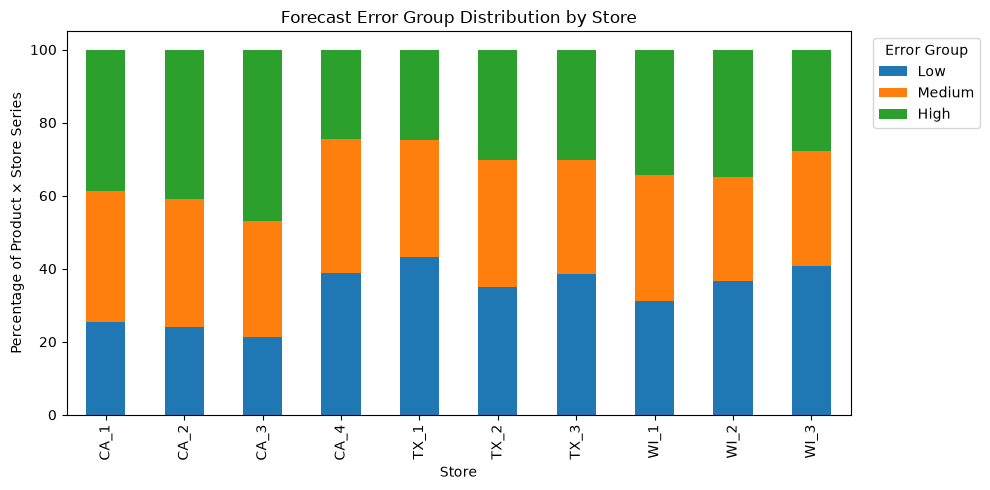

In [105]:
store_profile_plot = store_profile.set_index("store_id")

ax = store_profile_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Forecast Error Group Distribution by Store")
plt.xlabel("Store")
plt.ylabel("Percentage of Product × Store Series")

ax.legend(
    title="Error Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### Store — Key Observation

The distribution of forecast error groups differs across stores.

- CA_3 has the highest proportion of High-Error series at 47.03%.
- CA_2 and CA_1 have 40.80% and 38.64% High-Error series, respectively.
- CA_4 has 38.70% Low-Error series and 24.47% High-Error series.
- TX_1 has the highest proportion of Low-Error series at 43.23%.
- WI_3 also has a relatively high proportion of Low-Error series at 40.83%.
- WI_1 has a relatively balanced distribution across the three error groups.

### 16.7 State Profile

The error groups are compared across states to examine whether the distribution of Low, Medium, and High forecast-error Product × Store series differs by state.

In [106]:
state_profile = (
    forecast_error[["item_id", "store_id", "state_id"]]
    .drop_duplicates()
    .merge(
        series_error[["item_id", "store_id", "Error_Group"]],
        on=["item_id", "store_id"],
        how="inner"
    )
)

state_profile = pd.crosstab(
    state_profile["state_id"],
    state_profile["Error_Group"],
    normalize="index"
).mul(100).reset_index()

state_profile

Error_Group,state_id,Low,Medium,High
0,CA,27.345031,34.921286,37.733683
1,TX,38.908932,32.742976,28.348092
2,WI,36.186728,31.540396,32.272876


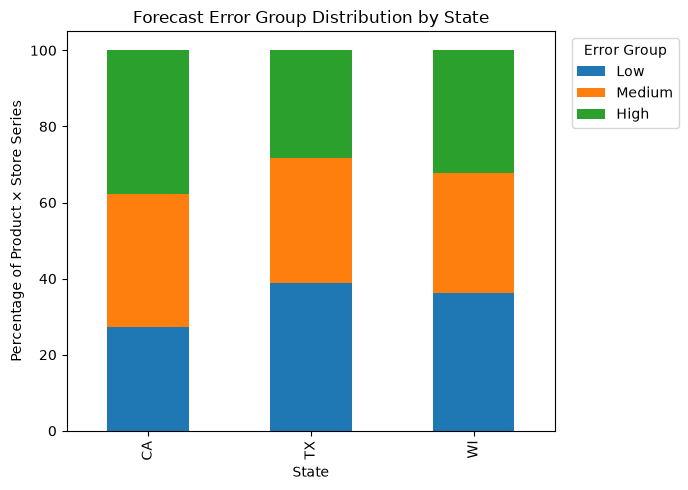

In [107]:
state_profile_plot = state_profile.set_index("state_id")

ax = state_profile_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5)
)

plt.title("Forecast Error Group Distribution by State")
plt.xlabel("State")
plt.ylabel("Percentage of Product × Store Series")

ax.legend(
    title="Error Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### State — Key Observation

The distribution of forecast error groups differs across states.

- CA has 37.73% of Product × Store series in the High-Error group.
- TX has the highest proportion of Low-Error series at 38.91% and 28.35% High-Error series.
- WI has 36.19% Low-Error and 32.27% High-Error series.
- CA shows a relatively higher proportion of High-Error series than TX and WI.

#### High-Error Segmentation Profile Summary

The High-Error group consists of Product × Store series with the highest one-third of MAE values during the 28-day evaluation period.

The profile of this group is summarized below:

| Characteristic | High-Error Group Observation |
|---|---|
| Demand volume | Median evaluation-period demand was 58 units |
| Intermittency | Median historical zero-demand rate was 49.82% |
| Volatility | Median historical CV was 142.59% |
| Category | FOODS had the largest proportion of High-Error series at 47.43% |
| Department | FOODS_3 had the largest proportion of High-Error series at 50.29% |
| Store | CA_3 had the largest proportion of High-Error series at 47.03% |
| State | CA had the largest proportion of High-Error series at 37.73% |

Overall, the High-Error group contains Product × Store series with higher evaluation-period demand volume and lower historical intermittency and volatility than the Low-Error group.

The distribution of High-Error series also varies across categories, departments, stores, and states.

## 17. Forecast Error Driver Analysis

This section synthesizes the findings from the forecast-error analysis to identify the demand characteristics and business segments associated with higher forecast error.

The analysis does not establish causal relationships. Instead, it identifies characteristics that are associated with forecast error during the 28-day evaluation period.

The diagnosis considers:

- Where forecast error is concentrated
- Demand volume
- Demand intermittency
- Demand volatility
- Time-related patterns
- Event periods
- SNAP Periods
- Selling price
- Product and geographic segments

The findings from the previous sections are brought together to form an evidence-based diagnosis of forecasting difficulty.

### 17.1 Where Is Forecast Error Concentrated?

The forecast-error analysis shows that error is not distributed uniformly across the retail business.

Differences were observed across:

- Product categories
- Departments
- Stores
- States
- Individual Product × Store demand series

The High-Error Segmentation also showed that the proportion of High-Error Product × Store series varies across these business segments.

Therefore, forecast performance differs across products and geographic segments rather than being consistent across the entire demand portfolio.

| Dimension | Key Finding |
|---|---|
| Category | FOODS has the highest proportion of High-Error series at 47.43%. |
| Department | FOODS_3 has the highest proportion of High-Error series at 50.29%. |
| Store | CA_3 has the highest proportion of High-Error series at 47.03%. |
| State | CA has the highest proportion of High-Error series at 37.73%. |

##### Key Observation

Forecast error is concentrated differently across product and geographic segments.

Within the High-Error segmentation, FOODS, FOODS_3, CA_3, and CA show relatively larger proportions of High-Error Product × Store series.

These differences indicate that forecast performance varies by business segment and geographic location.

### 17.2 What Demand Characteristics Are Associated With Higher Error?

The previous analyses examined individual demand characteristics and their relationship with forecast error.

The main associations observed during the evaluation period are summarized below.

| Demand Characteristic | Observed Association with Forecast Error |
|---|---|
| Demand Volume | Higher-demand Product × Store series had higher absolute error (MAE), while their relative error (WAPE) was lower. |
| Intermittency | Higher intermittency was associated with higher WAPE but lower MAE. In the High-Error segmentation based on MAE, High-Error series had lower historical intermittency than Low-Error series. |
| Volatility | Higher volatility was associated with higher WAPE but lower MAE. In the High-Error segmentation based on MAE, High-Error series had lower historical CV than Low-Error series. |
| Weekday Pattern | WAPE was generally higher on weekdays, particularly Tuesday–Thursday, than on weekends. |
| Within-Month Pattern | WAPE increased from the beginning toward the end of the month across the three forecasting methods. |
| Event Periods | Event days had lower WAPE than non-event days across all three forecasting methods during the evaluation period. |
| Selling Price | Higher price groups were associated with higher WAPE but lower MAE. |
| SNAP Periods          | SNAP-active days had lower WAPE than non-SNAP days across all three states and forecasting methods during the evaluation period. |


### Key Observation

The relationship between demand characteristics and forecast error depends on how forecast error is measured.

WAPE shows higher relative error for more intermittent, volatile, and higher-priced demand series, while MAE shows higher absolute error for higher-volume series.

SNAP-active days were associated with lower relative forecast error during the evaluation period, although this does not establish a causal relationship.

Therefore, no single demand characteristic explains forecast error across all error measures. The observed relationships should be interpreted as associations within the specific 28-day evaluation period.

## 18. Targeted Ad-Hoc Analysis

### 18.1 FOODS_3 Store-Level Drilldown

FOODS_3 had the highest proportion of High-Error Product × Store series among the departments.

This raises the question:

> Is the higher forecast error in FOODS_3 distributed across stores, or concentrated in particular stores?

The analysis below compares the distribution of Low, Medium, and High forecast-error series for FOODS_3 across stores.

In [116]:
foods3_store_profile = (
    forecast_error[
        forecast_error["dept_id"] == "FOODS_3"
    ][["item_id", "store_id"]]
    .drop_duplicates()
    .merge(
        series_error[
            ["item_id", "store_id", "Error_Group"]
        ],
        on=["item_id", "store_id"],
        how="inner"
    )
)

foods3_store_profile = pd.crosstab(
    foods3_store_profile["store_id"],
    foods3_store_profile["Error_Group"],
    normalize="index"
).mul(100).reset_index()

foods3_store_profile

Error_Group,store_id,Low,Medium,High
0,CA_1,9.842041,28.554070,61.603888
1,CA_2,10.328068,31.227217,58.444714
2,CA_3,8.991495,26.488457,64.520049
3,CA_4,19.441069,39.246659,41.312272
4,TX_1,31.956258,31.713244,36.330498
5,TX_2,22.357230,34.264885,43.377886
6,TX_3,24.422843,32.199271,43.377886
7,WI_1,11.664642,34.143378,54.191981
8,WI_2,15.795869,30.619684,53.584447
9,WI_3,20.413123,33.414338,46.172539


##### Key Observation

The High-Error proportion in FOODS_3 varies across stores.

- CA_3 has the highest proportion of High-Error series at 64.52%.
- CA_1 follows at 61.60%.
- CA_2 has 58.44% High-Error series.
- WI_1 and WI_2 have 54.19% and 53.58% High-Error series, respectively.
- CA_4 has a lower High-Error proportion of 41.31%.
- TX_1 has the lowest High-Error proportion at 36.33%.

Therefore, the high forecast error observed for FOODS_3 is not distributed uniformly across stores. The proportion of High-Error series is higher in some stores, particularly CA_1, CA_2, and CA_3.

## 19. Business Diagnosis

The forecast-error analysis indicates that forecasting difficulty is not uniform across the demand portfolio.

### 19.1 Forecast Performance Varies by Demand Segment

**Finding:**  
High forecast error is concentrated differently across categories, departments, stores, and states.

**Evidence:**  
FOODS, FOODS_3, and selected stores such as CA_3 showed relatively higher proportions of High-Error Product × Store series.

**Business implication:**  
Forecast performance should be monitored at relevant product and store levels rather than only at an overall level.

### 19.2 Demand Characteristics Affect Error Differently

**Finding:**  
Demand volume, intermittency, and volatility show different relationships with absolute and relative forecast error.

**Evidence:**  
Higher-volume series had higher MAE but lower WAPE, while higher intermittency and volatility were associated with higher WAPE.

**Business implication:**  
Both absolute and relative error measures are needed to properly evaluate forecasting performance across different demand profiles.

### 19.3 Calendar and Demand-Environment Patterns Are Associated With Forecast Error

**Finding:**  

Forecast error varies across calendar periods and different demand environments.

**Evidence:**  

WAPE was generally higher on weekdays and increased toward the end of the month during the evaluation period. SNAP-active days showed lower WAPE than non-SNAP days across California, Texas, and Wisconsin for all three forecasting methods.

**Business implication:**  

Calendar and demand-environment patterns should be considered when monitoring forecast performance, as forecast behavior can differ across different periods and demand conditions.

### 19.4 Simple Forecasting Has Planning Limitations

**Finding:**  
Forecast performance varied substantially across Product × Store series and demand characteristics.

**Evidence:**  
Product × Store WAPE was highly dispersed, while the three simple forecasting methods showed different error magnitudes and directional bias.

**Business implication:**  
A single simple forecasting approach may not provide consistent performance across all demand series, so higher-error segments require closer monitoring and potentially more tailored forecasting approaches.

## 20. Business Insights

1. **Forecast performance varies substantially across the demand portfolio.**  
   Error levels differ across Product × Store series, categories, departments, and stores, indicating that overall forecast metrics can hide segment-level differences.

2. **Relative and absolute forecast error tell different stories.**  
   Higher-volume series showed larger absolute errors but lower relative errors, while highly intermittent and volatile series showed higher relative error. Both WAPE and MAE are therefore important for evaluating forecast performance.

3. **Calendar and demand-environment factors.**  
   Forecast error varied across weekdays, within-month periods, event periods, and SNAP-active periods, indicating that forecast performance can differ under different demand conditions.

4. **High-error demand is concentrated in specific business segments.**  
   FOODS and FOODS_3 contained relatively high proportions of High-Error Product × Store series, with differences also observed across stores and states.

5. **Simple forecasting methods have different error behavior across demand conditions.**  
   The 7-Day Moving Average showed lower WAPE and MAE across the diagnostic groups examined, while forecast bias varied by method and demand segment.

6. **Forecast monitoring should be segmented.**  
   Evaluating forecast performance only at the overall level can hide differences across products, stores, demand profiles, and time periods.

## 21. Business Recommendations

The following recommendations translate the forecast-error findings into practical actions for demand planning.

### 21.1 Focus on Products and Stores With Repeated Forecast Errors

Some products and stores had much larger differences between forecasted and actual sales than others.

**Recommendation:**  
Regularly review products and stores where forecasts repeatedly differ significantly from actual sales.

### 21.2 Give More Attention to Hard-to-Predict Products

Some products have regular sales patterns, while others have sparse or irregular sales.

**Recommendation:**  
Give closer attention to products with irregular sales patterns and review their forecasts more frequently.

### 21.3 Consider Both Units and Percentage Differences

A large difference in units can be important for a high-selling product, while a small difference can appear very large as a percentage for a low-selling product.

**Recommendation:**  
Consider both the number of units missed and the percentage difference when deciding which products need attention.

### 21.4 Consider Calendar Patterns

Sales patterns differed across weekdays and different periods of the month.

**Recommendation:**  
Pay closer attention to forecasts around recurring calendar periods where larger differences were observed.

### 21.5 Use the Recent 7-Day Average as a Practical Baseline

The recent 7-day sales average produced lower forecasting errors than the other simple approaches tested during the evaluation period.

**Recommendation:**  
Use the recent 7-day sales average as a practical starting point for short-term demand planning and monitor where it performs poorly.

### 21.6 Investigate Persistent Forecast Problems

The analysis identifies patterns associated with forecast errors but does not establish the underlying business causes.

**Recommendation:**  
When forecasting problems persist, investigate factors such as promotions, product availability, assortment changes, and other business events before changing the forecasting approach.

## 22. Export Analytical Results

The final analytical results are exported for use in the Power BI reporting stage.

Only tables required for business reporting and dashboard analysis are exported. Intermediate calculations and temporary analysis tables are not exported.

#### 22.1 Series Error Summary

In [117]:
series_error_summary = series_error[
    [
        "item_id",
        "store_id",
        "Actual_Demand",
        "Absolute_Error",
        "MAE",
        "WAPE",
        "Error_Group"
    ]
].copy()

series_error_summary.head()

,item_id,store_id,Actual_Demand,Absolute_Error,MAE,WAPE,Error_Group
0,FOODS_1_001,CA_1,23,31.285714,1.117347,136.024845,High
1,FOODS_1_001,CA_2,18,32.571429,1.163265,180.952381,High
2,FOODS_1_001,CA_3,27,27.000000,0.964286,100.000000,Medium
3,FOODS_1_001,CA_4,6,17.428571,0.622449,290.476190,Medium
4,FOODS_1_001,TX_1,26,26.000000,0.928571,100.000000,Medium


In [118]:
product_store_mapping = (
    forecast_error[
        [
            "item_id",
            "store_id",
            "dept_id",
            "cat_id",
            "state_id"
        ]
    ]
    .drop_duplicates()
)

series_error_summary = series_error_summary.merge(
    product_store_mapping,
    on=["item_id", "store_id"],
    how="left"
)

series_error_summary.head()

,item_id,store_id,Actual_Demand,Absolute_Error,MAE,WAPE,Error_Group,dept_id,cat_id,state_id
0,FOODS_1_001,CA_1,23,31.285714,1.117347,136.024845,High,FOODS_1,FOODS,CA
1,FOODS_1_001,CA_2,18,32.571429,1.163265,180.952381,High,FOODS_1,FOODS,CA
2,FOODS_1_001,CA_3,27,27.000000,0.964286,100.000000,Medium,FOODS_1,FOODS,CA
3,FOODS_1_001,CA_4,6,17.428571,0.622449,290.476190,Medium,FOODS_1,FOODS,CA
4,FOODS_1_001,TX_1,26,26.000000,0.928571,100.000000,Medium,FOODS_1,FOODS,TX


In [119]:
series_error_summary.shape

(30490, 10)

In [120]:
series_error_summary.isna().sum()

item_id             0
store_id            0
Actual_Demand       0
Absolute_Error      0
MAE                 0
WAPE              666
Error_Group         0
dept_id             0
cat_id              0
state_id            0
dtype: int64

In [121]:
series_error_summary.duplicated().sum()

np.int64(0)

In [122]:
series_error_summary.to_csv(
    "../data/processed/analytical/series_error_summary.csv",
    index=False
)

In [123]:
import os

os.path.getsize(
    "../data/processed/analytical/series_error_summary.csv"
)

2929505

#### 22.2 Category Error Summary

In [124]:
category_error_summary = (
    forecast_error
    .groupby("cat_id")
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["actual_demand"].sum(),

            "WAPE_Naive": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Naive": x["absolute_error_naive"].mean(),

            "Bias_Naive": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Moving_Average": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Moving_Average": x["absolute_error_moving_average"].mean(),

            "Bias_Moving_Average": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Seasonal_Naive": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Seasonal_Naive": x["absolute_error_seasonal_naive"].mean(),

            "Bias_Seasonal_Naive": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        })
    )
    .reset_index()
)

category_error_summary

,cat_id,Actual_Demand,WAPE_Naive,MAE_Naive,Bias_Naive,WAPE_Moving_Average,MAE_Moving_Average,Bias_Moving_Average,WAPE_Seasonal_Naive,MAE_Seasonal_Naive,Bias_Seasonal_Naive
0,FOODS,832488.0,86.776987,1.795427,9.828850,67.351876,1.393519,-9.027878,78.665638,1.627602,-9.027878
1,HOBBIES,115856.0,127.922594,0.936827,13.178428,102.954160,0.753973,-5.089076,118.645560,0.868887,-5.089076
2,HOUSEHOLD,283420.0,106.399690,1.028646,23.076706,81.872940,0.791528,-3.385788,95.146426,0.919853,-3.385788


In [125]:
category_error_summary.to_csv(
    "../data/processed/analytical/category_error_summary.csv",
    index=False
)

In [126]:
import os

os.path.getsize(
    "../data/processed/analytical/category_error_summary.csv"
)

730

#### 22.3 Department Error Summary

In [127]:
department_error_summary = (
    forecast_error
    .groupby("dept_id")
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["actual_demand"].sum(),

            "WAPE_Naive": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Naive": x["absolute_error_naive"].mean(),

            "Bias_Naive": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Moving_Average": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Moving_Average": x["absolute_error_moving_average"].mean(),

            "Bias_Moving_Average": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Seasonal_Naive": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Seasonal_Naive": x["absolute_error_seasonal_naive"].mean(),

            "Bias_Seasonal_Naive": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        })
    )
    .reset_index()
)

department_error_summary

,dept_id,Actual_Demand,WAPE_Naive,MAE_Naive,Bias_Naive,WAPE_Moving_Average,MAE_Moving_Average,Bias_Moving_Average,WAPE_Seasonal_Naive,MAE_Seasonal_Naive,Bias_Seasonal_Naive
0,FOODS_1,102359.0,96.055061,1.625678,-12.875272,80.903905,1.369253,-20.409539,93.053859,1.574884,-20.409539
1,FOODS_2,165203.0,100.078691,1.483606,9.709872,76.298770,1.131083,-12.011283,89.629728,1.328706,-12.011283
2,FOODS_3,564926.0,81.206034,1.990774,13.977406,62.280015,1.526801,-6.093187,72.852374,1.785983,-6.093187
3,HOBBIES_1,102554.0,125.153578,1.101906,15.381165,99.502980,0.876067,-2.825828,116.003276,1.021343,-2.825828
4,HOBBIES_2,13302.0,149.270786,0.475935,-3.803939,129.561613,0.413094,-22.537964,139.016689,0.443241,-22.537964
5,HOUSEHOLD_1,222327.0,96.701255,1.443294,23.358836,72.600847,1.083588,-3.139070,86.292263,1.287936,-3.139070
6,HOUSEHOLD_2,61093.0,141.693811,0.600312,22.049989,115.615537,0.489827,-4.283633,127.368111,0.539619,-4.283633


In [128]:
department_error_summary.to_csv(
    "../data/processed/analytical/department_error_summary.csv",
    index=False
)

In [129]:
os.path.getsize(
    "../data/processed/analytical/department_error_summary.csv"
)

1490

#### 22.4 Store Error Summary

In [130]:
store_error_summary = (
    forecast_error
    .groupby("store_id")
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["actual_demand"].sum(),

            "WAPE_Naive": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Naive": x["absolute_error_naive"].mean(),

            "Bias_Naive": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Moving_Average": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Moving_Average": x["absolute_error_moving_average"].mean(),

            "Bias_Moving_Average": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Seasonal_Naive": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Seasonal_Naive": x["absolute_error_seasonal_naive"].mean(),

            "Bias_Seasonal_Naive": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        })
    )
    .reset_index()
)

store_error_summary

,store_id,Actual_Demand,WAPE_Naive,MAE_Naive,Bias_Naive,WAPE_Moving_Average,MAE_Moving_Average,Bias_Moving_Average,WAPE_Seasonal_Naive,MAE_Seasonal_Naive,Bias_Seasonal_Naive
0,CA_1,134032.0,99.859735,1.567774,27.703832,74.981241,1.177188,-5.556882,86.801659,1.362765,-5.556882
1,CA_2,132920.0,104.396630,1.625404,28.119169,76.006406,1.183382,-7.077942,87.569967,1.363421,-7.077942
2,CA_3,175360.0,91.578467,1.881085,23.282391,67.258700,1.381540,-2.447536,80.311359,1.649651,-2.447536
3,CA_4,78858.0,112.817977,1.042098,16.142940,89.316420,0.825015,-2.117731,104.544878,0.965680,-2.117731
4,TX_1,97531.0,96.868688,1.106651,15.782674,77.544722,0.885889,-5.264993,89.107053,1.017980,-5.264993
5,TX_2,115258.0,91.349841,1.233285,4.266949,73.964993,0.998578,-7.876243,85.451769,1.153657,-7.876243
6,TX_3,116610.0,90.897865,1.241578,-4.985850,73.880701,1.009140,-12.491210,86.227596,1.177787,-12.491210
7,WI_1,112444.0,102.644872,1.351942,21.368859,76.615915,1.009113,-5.702394,89.491658,1.178700,-5.702394
8,WI_2,153976.0,81.972515,1.478447,-6.767288,67.979054,1.226063,-14.487972,79.807243,1.439395,-14.487972
9,WI_3,114775.0,89.400131,1.201905,5.510782,73.413324,0.986976,-9.001089,84.102810,1.130687,-9.001089


In [131]:
store_error_summary.to_csv(
    "../data/processed/analytical/store_error_summary.csv",
    index=False
)

In [132]:
os.path.getsize(
    "../data/processed/analytical/store_error_summary.csv"
)

1990

#### 22.5 State Error Summary

In [133]:
state_error_summary = (
    forecast_error
    .groupby("state_id")
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["actual_demand"].sum(),

            "WAPE_Naive": (
                x["absolute_error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Naive": x["absolute_error_naive"].mean(),

            "Bias_Naive": (
                x["error_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Moving_Average": (
                x["absolute_error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Moving_Average": x["absolute_error_moving_average"].mean(),

            "Bias_Moving_Average": (
                x["error_moving_average"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "WAPE_Seasonal_Naive": (
                x["absolute_error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100,

            "MAE_Seasonal_Naive": x["absolute_error_seasonal_naive"].mean(),

            "Bias_Seasonal_Naive": (
                x["error_seasonal_naive"].sum()
                / x["actual_demand"].sum()
            ) * 100
        })
    )
    .reset_index()
)

state_error_summary

,state_id,Actual_Demand,WAPE_Naive,MAE_Naive,Bias_Naive,WAPE_Moving_Average,MAE_Moving_Average,Bias_Moving_Average,WAPE_Seasonal_Naive,MAE_Seasonal_Naive,Bias_Seasonal_Naive
0,CA,521170.0,100.191108,1.529090,24.572788,74.813318,1.141781,-4.378226,87.498513,1.335379,-4.378226
1,TX,329399.0,92.823900,1.193838,4.401046,74.995067,0.964536,-8.736821,86.808703,1.116475,-8.736821
2,WI,381195.0,90.306798,1.344098,5.229082,72.162954,1.074051,-10.244363,83.957292,1.249594,-10.244363


In [134]:
state_error_summary.to_csv(
    "../data/processed/analytical/state_error_summary.csv",
    index=False
)

In [135]:
os.path.getsize(
    "../data/processed/analytical/state_error_summary.csv"
)

713

#### 22.6 Daily Demand Summary

In [136]:
daily_demand_summary = (
    forecast_error
    .groupby(["d", "date"])
    .agg(
        Actual_Demand=("actual_demand", "sum"),
        Forecast_Naive=("forecast_naive", "sum"),
        Forecast_Moving_Average=("forecast_moving_average", "sum"),
        Forecast_Seasonal_Naive=("forecast_seasonal_naive", "sum")
    )
    .reset_index()
)

daily_demand_summary

,d,date,Actual_Demand,Forecast_Naive,Forecast_Moving_Average,Forecast_Seasonal_Naive
0,d_1914,2016-04-25,38793,49795,40754.142857,38059
1,d_1915,2016-04-26,35487,49795,40754.142857,37570
2,d_1916,2016-04-27,34445,49795,40754.142857,35343
3,d_1917,2016-04-28,34732,49795,40754.142857,35033
4,d_1918,2016-04-29,42896,49795,40754.142857,40517
5,d_1919,2016-04-30,50429,49795,40754.142857,48962
6,d_1920,2016-05-01,53032,49795,40754.142857,49795
7,d_1921,2016-05-02,43181,49795,40754.142857,38059
8,d_1922,2016-05-03,44314,49795,40754.142857,37570
9,d_1923,2016-05-04,39601,49795,40754.142857,35343


In [137]:
daily_demand_summary.to_csv(
    "../data/processed/analytical/daily_demand_summary.csv",
    index=False
)

In [138]:
os.path.getsize(
    "../data/processed/analytical/daily_demand_summary.csv"
)

1653

In [140]:
import os

analytical_path = "../data/processed/analytical"

os.listdir(analytical_path)

['category_error_summary.csv',
 'daily_demand_summary.csv',
 'department_error_summary.csv',
 'forecast_results.csv',
 'sales_evaluation.csv',
 'sales_historical.csv',
 'series_error_summary.csv',
 'state_error_summary.csv',
 'store_error_summary.csv']

##### Export Summary

The final analytical tables required for reporting and dashboard development have been exported to the analytical data folder.

The exported tables contain forecast performance at overall, Product × Store, category, department, store, state, and daily levels.

Intermediate analysis tables were not exported because they were used only for diagnostic analysis.